In [1]:
# model pruning and quantization

In [2]:
import os
os.environ["XLA_FLAGS"]="--xla_gpu_cuda_data_dir=C:/Users/USER/anaconda3/envs/tf-gpu/Library/bin"

# to avoid pruning errors

In [3]:
import tensorflow as tf
import numpy as np
import random

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

In [4]:
index = 'vabc' # 'tgi', 'vabc', 'ngrdi' # if use vabc, need manual model finding
model = 'VGGNet'
augmented = True
norm = 'zs'

In [5]:
import os

folder_path = f'pruned/{index}/'

os.makedirs(folder_path, exist_ok=True)

In [6]:
import os

idx = 0

bm_name = f"{folder_path}pruned_{norm}{'_augmented' if augmented == True else ''}_{index}_{model}.h5" # best model name 

# while os.path.exists(bm_name) == True:
#     bm_name = f"{folder_path}pruned_{norm}{'_augmented' if augmented == True else ''}_{index}_{model}_{idx}.h5" # best model name 
#     idx += 1

idx = 0

lm_name = f"{folder_path}last_pruned_{norm}{'_augmented' if augmented == True else ''}_{index}_{model}.h5" # last model name

# while os.path.exists(lm_name) == True:
#     lm_name = f"{folder_path}last_pruned_{norm}{'_augmented' if augmented == True else ''}_{index}_{model}_{idx}.h5" # last model name
#     idx += 1

In [7]:
bm_name

'pruned/vabc/pruned_zs_augmented_vabc_VGGNet.h5'

# Load Data

In [8]:
# import dataset

import cv2 as cv
import os

representative_data = []

rep_path = 'representative_data'

print(rep_path)

for image_name in os.listdir(rep_path):
    img = cv.imread(os.path.join(rep_path, image_name))
    representative_data.append(img)

representative_data


In [9]:
x_test = []
y_test = []

test_path = 'test'

for classes in os.listdir(test_path):
    class_path = os.path.join(test_path, classes)
    for image_name in os.listdir(class_path):
        img = cv.imread(os.path.join(class_path, image_name))
        x_test.append(img)
        y_test.append(classes)

In [10]:
import func

y_test = func.Preprocessing.convert_to_numeric(y_test)

In [11]:
rep_index = []

for x in representative_data:
    x_temp = func.Preprocessing.convert_to_indices(x, index)
    x_temp = func.Preprocessing.global_z_score_normalization(x_temp, index)
    rep_index.append(x_temp)

del representative_data

test_index = []

for x in x_test:
    x_temp = func.Preprocessing.convert_to_indices(x, index)
    x_temp = func.Preprocessing.global_z_score_normalization(x_temp, index)
    test_index.append(x_temp)

del x_test

In [12]:
import tensorflow as tf
from tensorflow.keras.utils import to_categorical

test_index = tf.convert_to_tensor(test_index, dtype=tf.float32)
y_test = tf.convert_to_tensor(y_test, dtype=tf.float32)

y_test = to_categorical(y_test, num_classes=10)

Load best pruned model

In [13]:
import tensorflow_model_optimization as tfmot

with tfmot.sparsity.keras.prune_scope():
    final_pruned_model = tf.keras.models.load_model(bm_name)

In [14]:
best_pruned = tfmot.sparsity.keras.strip_pruning(final_pruned_model)

In [15]:
best_pruned.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4), loss=tf.keras.losses.CategoricalCrossentropy(), metrics=[tf.keras.metrics.CategoricalAccuracy(), tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])

In [16]:
eval_score = best_pruned.evaluate(test_index, y_test, batch_size=16, steps=len(test_index)/16)

170/170 [==============================] - 5s 7ms/step - loss: 0.1076 - categorical_accuracy: 0.9651 - precision: 0.9679 - recall: 0.9622


86/86 [==============================] - 1s 10ms/step


<Axes: title={'center': 'Pruned LI-VGGNet Confusion Matrix'}>

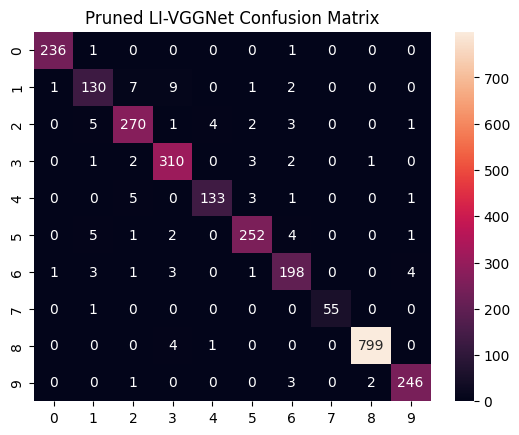

In [17]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

pruned_pred = best_pruned.predict(test_index)
pruned_pred_labels = tf.argmax(pruned_pred, axis=1)
y_test_labels = tf.argmax(y_test, axis=1)

plt.title(f"Pruned LI-{model} Confusion Matrix")
sns.heatmap(func.Visualization.visualize_conf_matrix(y_test, pruned_pred), annot=True, fmt="g")

In [18]:
print(classification_report(y_test_labels, pruned_pred_labels))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       238
           1       0.89      0.87      0.88       150
           2       0.94      0.94      0.94       286
           3       0.94      0.97      0.96       319
           4       0.96      0.93      0.95       143
           5       0.96      0.95      0.96       265
           6       0.93      0.94      0.93       211
           7       1.00      0.98      0.99        56
           8       1.00      0.99      1.00       804
           9       0.97      0.98      0.97       252

    accuracy                           0.97      2724
   macro avg       0.96      0.95      0.96      2724
weighted avg       0.97      0.97      0.97      2724



# Quantization

In [19]:
def representative_data_gen():
    for image in rep_index:
        yield [image.reshape(1, 256, 256, 1)]

converter = tf.lite.TFLiteConverter.from_keras_model(best_pruned)

converter.representative_dataset = representative_data_gen # rep data must be float32 for callibration

converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_quant_model = converter.convert()

INFO:tensorflow:Assets written to: C:\Users\USER\AppData\Local\Temp\tmp6f8f0uay\assets


INFO:tensorflow:Assets written to: C:\Users\USER\AppData\Local\Temp\tmp6f8f0uay\assets
c:\Users\USER\anaconda3\envs\tf-gpu\lib\site-packages\tensorflow\lite\python\convert.py:766: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn("Statistics for quantized inputs were expected, but not "


In [20]:
new_folder_path = f'requant/{index}/requant'

In [21]:
q_name = f"{new_folder_path}_{norm}{'_augmented' if augmented == True else ''}_{index}_{model}.tflite"

idx = 0

while os.path.exists(q_name) == True:
    q_name = f"{new_folder_path}_{norm}{'_augmented' if augmented == True else ''}_{index}_{model}_{idx}.tflite" # best model name 
    idx += 1

In [22]:
q_name

'requant/vabc/requant_zs_augmented_vabc_VGGNet.tflite'

In [23]:
with open(q_name, 'wb') as f:
    f.write(tflite_quant_model)

In [24]:
interpreter = tf.lite.Interpreter(model_path=q_name)
interpreter.allocate_tensors()

In [25]:
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("== Input details ==")
print("name:", input_details[0]['name'])
print("shape:", input_details[0]['shape'])
print("type:", input_details[0]['dtype'])

print("\n== Output details ==")
print("name:", output_details[0]['name'])
print("shape:", output_details[0]['shape'])
print("type:", output_details[0]['dtype'])

== Input details ==
name: serving_default_Input_Layer:0
shape: [  1 256 256   1]
type: <class 'numpy.int8'>

== Output details ==
name: StatefulPartitionedCall:0
shape: [ 1 10]
type: <class 'numpy.int8'>


In [26]:
input_scale = input_details[0]['quantization'][0]
input_zero_point = input_details[0]['quantization'][1]

test_data = np.array(np.round(test_index / input_scale + input_zero_point).astype(np.int8)).reshape(-1, 256, 256, 1)

In [27]:
all_predictions = []
all_true_labels = []

In [28]:
def evaluate_tflite_model(interpreter, test_data, test_labels):
    total_samples = len(test_data)

    for i in range(total_samples):
        input_data = np.expand_dims(test_data[i], axis=0).astype(input_details[0]['dtype'])

        interpreter.set_tensor(input_details[0]['index'], input_data)

        interpreter.invoke()

        output_data = interpreter.get_tensor(output_details[0]['index'])
        predicted_label = np.argmax(output_data, axis=1)[0]

        # Store predictions and true labels
        all_predictions.append(predicted_label)
        all_true_labels.append(test_labels[i])

    print("Evaluation complete!")

In [29]:
evaluate_tflite_model(interpreter, test_data, y_test)

Evaluation complete!


<Axes: title={'center': 'Post-Quantization LI-VGGNet Confusion Matrix'}>

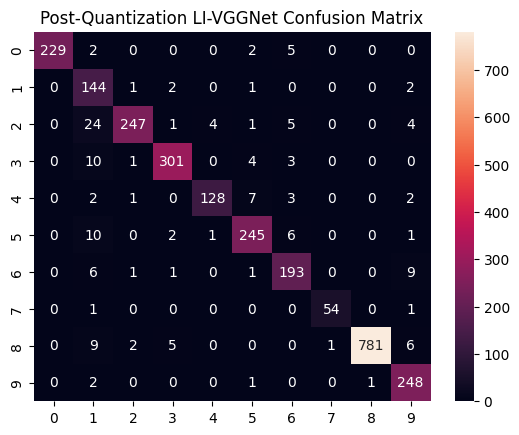

In [30]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score

conv_true_labels = np.argmax(all_true_labels, axis=1)

# conf_matrix = confusion_matrix(all_true_labels, all_predictions)
plt.title(f"Post-Quantization LI-{model} Confusion Matrix")
sns.heatmap(confusion_matrix(conv_true_labels, all_predictions), annot=True, fmt="g")

In [31]:
print(classification_report(conv_true_labels, all_predictions))

              precision    recall  f1-score   support

           0       1.00      0.96      0.98       238
           1       0.69      0.96      0.80       150
           2       0.98      0.86      0.92       286
           3       0.96      0.94      0.95       319
           4       0.96      0.90      0.93       143
           5       0.94      0.92      0.93       265
           6       0.90      0.91      0.91       211
           7       0.98      0.96      0.97        56
           8       1.00      0.97      0.98       804
           9       0.91      0.98      0.94       252

    accuracy                           0.94      2724
   macro avg       0.93      0.94      0.93      2724
weighted avg       0.95      0.94      0.95      2724



In [32]:
accuracy = accuracy_score(conv_true_labels, all_predictions)
precision = precision_score(conv_true_labels, all_predictions, average='weighted')
recall = recall_score(conv_true_labels, all_predictions, average='weighted')

In [33]:
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

Accuracy: 0.9435
Precision: 0.9506
Recall: 0.9435
